# Bài 5: Gom cụm bộ dữ liệu MNIST bằng thuật toán k-Means

Dựa trên dữ liệu MNIST đã làm quen ở bài thực hành trước, thực hiện gom cụm bằng thuật toán **k-Means** (k = 10, tương ứng 10 chữ số từ 0 đến 9). Sau đó so sánh kết quả gom cụm với nhãn lớp có sẵn của dữ liệu.

## 1. Đọc và tiền xử lý dữ liệu

In [1]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.cluster import KMeans
from sklearn.metrics import (confusion_matrix, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score,
                             completeness_score, v_measure_score)

# Đọc dữ liệu MNIST
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Kích thước train:", train_images.shape, train_labels.shape)
print("Kích thước test:", test_images.shape, test_labels.shape)

# Chuẩn hóa pixel về [0,1] và duỗi ảnh 28x28 thành vector 784 chiều
img_shape = train_images.shape[1:]
X_train = (train_images.astype('float32') / 255.0).reshape(len(train_images), -1)
X_test = (test_images.astype('float32') / 255.0).reshape(len(test_images), -1)
y_train, y_test = train_labels, test_labels
print("Kích thước X_train sau khi duỗi:", X_train.shape)

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước train: (60000, 28, 28) (60000,)
Kích thước test: (10000, 28, 28) (10000,)
Kích thước X_train sau khi duỗi: (60000, 784)


## 2. Gom cụm bằng k-Means (k = 10)

In [2]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
kmeans = KMeans(n_clusters=10, n_init=10, random_state=42)
kmeans.fit(X_train)

train_clusters = kmeans.labels_
test_clusters = kmeans.predict(X_test)

print("Inertia (tổng bình phương khoảng cách tới tâm cụm):", round(kmeans.inertia_, 2))
print("\nSố mẫu trong từng cụm (train):")
for c, n in zip(*np.unique(train_clusters, return_counts=True)):
    print(f"  Cụm {c}: {n} mẫu")

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Inertia (tổng bình phương khoảng cách tới tâm cụm): 2352815.5

Số mẫu trong từng cụm (train):
  Cụm 0: 8839 mẫu
  Cụm 1: 5960 mẫu
  Cụm 2: 3098 mẫu
  Cụm 3: 5714 mẫu
  Cụm 4: 3198 mẫu
  Cụm 5: 8929 mẫu
  Cụm 6: 6515 mẫu
  Cụm 7: 4674 mẫu
  Cụm 8: 7435 mẫu
  Cụm 9: 5638 mẫu


### Hiển thị tâm của 10 cụm

Mỗi tâm cụm là một vector 784 chiều, được vẽ lại thành ảnh 28x28.

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


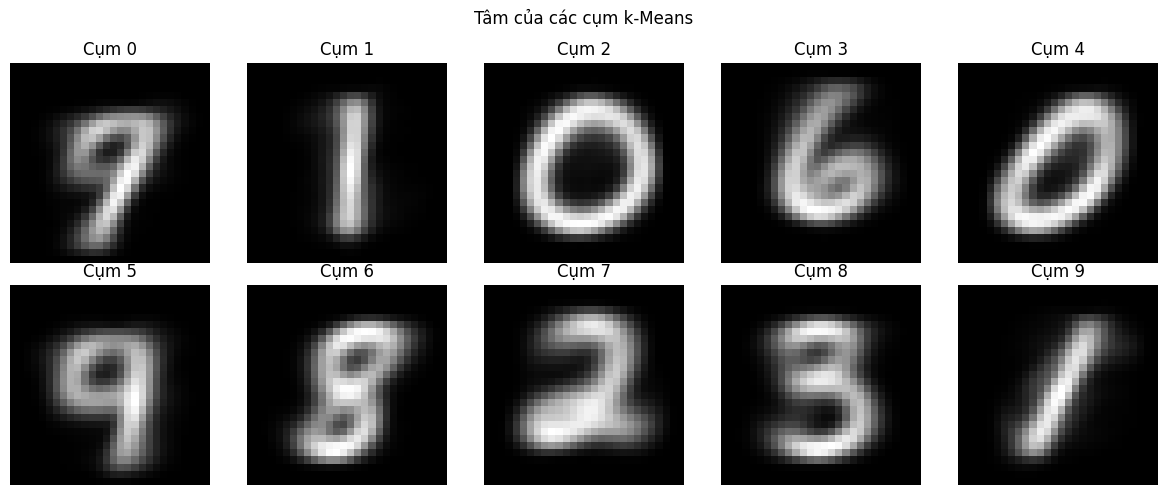

In [3]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(kmeans.cluster_centers_[i].reshape(img_shape), cmap='gray')
    ax.set_title(f"Cụm {i}")
    ax.axis('off')
plt.suptitle("Tâm của các cụm k-Means")
plt.tight_layout()
plt.show()

## 3. So sánh kết quả gom cụm với nhãn lớp có sẵn

### 3.1. Bảng đối chiếu giữa cụm và nhãn thật (tập train)

Mỗi dòng là một cụm, mỗi cột là một chữ số thật; giá trị là số mẫu.

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


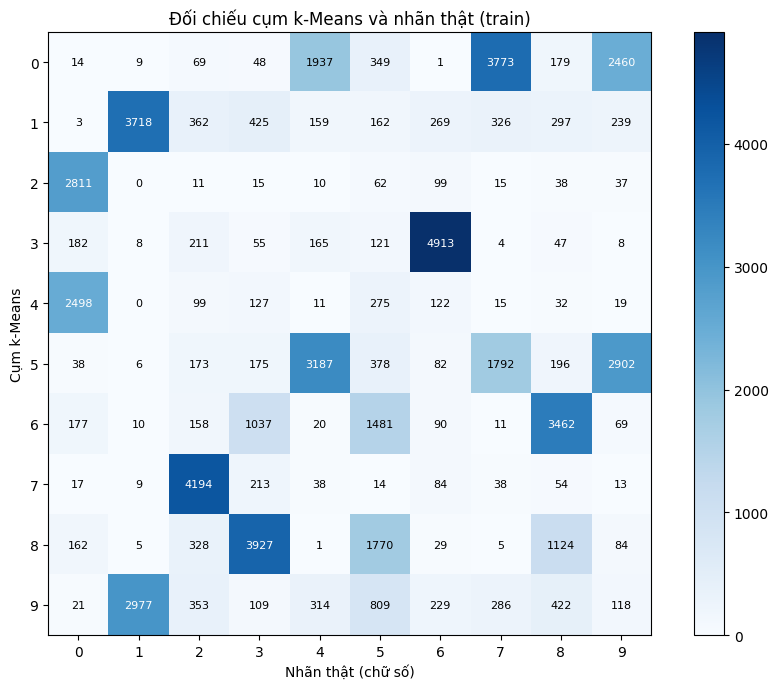

In [4]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
# Ma trận đối chiếu: hàng = cụm, cột = nhãn thật
contingency = np.zeros((10, 10), dtype=int)
for c, t in zip(train_clusters, y_train):
    contingency[c, t] += 1

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(contingency, cmap='Blues')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Nhãn thật (chữ số)")
ax.set_ylabel("Cụm k-Means")
ax.set_title("Đối chiếu cụm k-Means và nhãn thật (train)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, contingency[i, j], ha='center', va='center',
                color='white' if contingency[i, j] > contingency.max() / 2 else 'black', fontsize=8)
plt.colorbar(im)
plt.tight_layout()
plt.show()

### 3.2. Gán nhãn cho từng cụm theo nhãn xuất hiện nhiều nhất và tính độ chính xác

In [5]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
# Mỗi cụm được gán nhãn là chữ số xuất hiện nhiều nhất trong cụm đó
cluster_to_label = {c: int(np.argmax(contingency[c])) for c in range(10)}
print("Nhãn được gán cho từng cụm:", cluster_to_label)

print("\nĐộ thuần khiết (purity) của từng cụm:")
for c in range(10):
    purity = contingency[c].max() / contingency[c].sum()
    print(f"  Cụm {c} -> chữ số {cluster_to_label[c]}: purity = {purity:.4f}")

# Dự đoán nhãn dựa trên cụm
y_train_pred = np.array([cluster_to_label[c] for c in train_clusters])
y_test_pred = np.array([cluster_to_label[c] for c in test_clusters])

print(f"\nĐộ chính xác (accuracy) trên tập train: {np.mean(y_train_pred == y_train):.4f}")
print(f"Độ chính xác (accuracy) trên tập test : {np.mean(y_test_pred == y_test):.4f}")

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Nhãn được gán cho từng cụm: {0: 7, 1: 1, 2: 0, 3: 6, 4: 0, 5: 4, 6: 8, 7: 2, 8: 3, 9: 1}

Độ thuần khiết (purity) của từng cụm:
  Cụm 0 -> chữ số 7: purity = 0.4269
  Cụm 1 -> chữ số 1: purity = 0.6238
  Cụm 2 -> chữ số 0: purity = 0.9074
  Cụm 3 -> chữ số 6: purity = 0.8598
  Cụm 4 -> chữ số 0: purity = 0.7811
  Cụm 5 -> chữ số 4: purity = 0.3569
  Cụm 6 -> chữ số 8: purity = 0.5314
  Cụm 7 -> chữ số 2: purity = 0.8973
  Cụm 8 -> chữ số 3: purity = 0.5282
  Cụm 9 -> chữ số 1: purity = 0.5280

Độ chính xác (accuracy) trên tập train: 0.5910
Độ chính xác (accuracy) trên tập test : 0.5945


### 3.3. Các độ đo đánh giá chất lượng gom cụm so với nhãn thật

In [6]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
print("Các độ đo trên tập train:")
print(f"  Adjusted Rand Index (ARI)        : {adjusted_rand_score(y_train, train_clusters):.4f}")
print(f"  Normalized Mutual Info (NMI)     : {normalized_mutual_info_score(y_train, train_clusters):.4f}")
print(f"  Homogeneity                      : {homogeneity_score(y_train, train_clusters):.4f}")
print(f"  Completeness                     : {completeness_score(y_train, train_clusters):.4f}")
print(f"  V-measure                        : {v_measure_score(y_train, train_clusters):.4f}")

print("\nCác độ đo trên tập test:")
print(f"  Adjusted Rand Index (ARI)        : {adjusted_rand_score(y_test, test_clusters):.4f}")
print(f"  Normalized Mutual Info (NMI)     : {normalized_mutual_info_score(y_test, test_clusters):.4f}")
print(f"  Homogeneity                      : {homogeneity_score(y_test, test_clusters):.4f}")
print(f"  Completeness                     : {completeness_score(y_test, test_clusters):.4f}")
print(f"  V-measure                        : {v_measure_score(y_test, test_clusters):.4f}")

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Các độ đo trên tập train:
  Adjusted Rand Index (ARI)        : 0.3609
  Normalized Mutual Info (NMI)     : 0.4906
  Homogeneity                      : 0.4851
  Completeness                     : 0.4963
  V-measure                        : 0.4906

Các độ đo trên tập test:
  Adjusted Rand Index (ARI)        : 0.3667
  Normalized Mutual Info (NMI)     : 0.4982
  Homogeneity                      : 0.4922
  Completeness                     : 0.5044
  V-measure                        : 0.4982


### 3.4. Confusion matrix sau khi gán nhãn cụm (tập test)

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


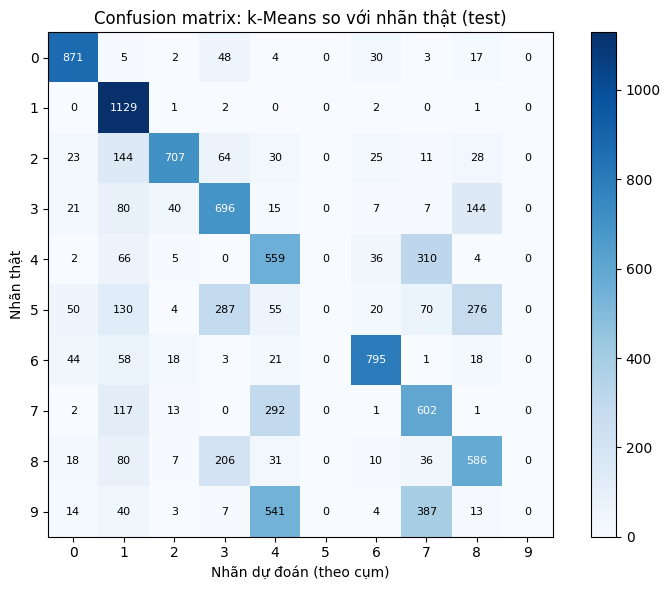

In [7]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Nhãn dự đoán (theo cụm)")
ax.set_ylabel("Nhãn thật")
ax.set_title("Confusion matrix: k-Means so với nhãn thật (test)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)
plt.colorbar(im)
plt.tight_layout()
plt.show()

### Nhận xét

- k-Means là thuật toán **không giám sát**, chỉ dựa vào khoảng cách giữa các ảnh (pixel) mà không biết nhãn; nhãn thật chỉ được dùng để đánh giá sau khi gom cụm.
- Các chữ số có hình dạng đặc trưng rõ như **0, 1, 6** thường được tách thành cụm khá thuần khiết.
- Các chữ số có nét tương tự như **4, 7, 9** hoặc **3, 5, 8** thường bị lẫn vào nhau trong cùng một cụm (xem bảng đối chiếu và confusion matrix), nên độ chính xác chỉ ở mức trung bình.
- Vì vậy kết quả gom cụm chỉ phản ánh tương đối nhãn thật; để phân loại chính xác hơn cần dùng các mô hình có giám sát như Neural Network ở các bài trước.